# Order-Level (L3) Limit Order Book Analysis

While the LOBSTER datasets offer message and order book data by the tick, they only include price level data within the top 10 snapshot. Unknown liquidity is therefore handled by genesis blocks: liquid abstractions at a given price level. 

Genesis blocks adhere to a conservative/pessimistic strategy, whereby they are always found at the front of the L3 queues (highest priority), which underestimates our order fill probability.

## Intraday Reconstruction Agreement

Each `<TICKER>_agreement.csv` holds one row per 5-minute bucket (78 buckets, 09:30-16:00) with **summable** counters. We load all five tickers, derive per-bucket ratios, and plot each metric over the trading day with one colour-coded line per ticker.

In [23]:
# Imports
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [24]:
# Load <TICKER>_agreement.csv
DATA_DIR = Path(".")
TICKERS = ["AAPL", "AMZN", "GOOG", "INTC", "MSFT"]

COLORS = {
    "AAPL": "#1f77b4",
    "AMZN": "#ff7f0e",
    "GOOG": "#2ca02c",
    "INTC": "#d62728",
    "MSFT": "#9467bd",
}

def load_ticker(ticker: str) -> pd.DataFrame:
    df = pd.read_csv(DATA_DIR / f"{ticker}_agreement.csv")

    df["time"] = pd.to_datetime(df["bucket_start"], format="%H:%M:%S")

    # Guard against divide-by-zero on empty buckets
    rows = df["rows"].replace(0, pd.NA)

    # Derived ratios
    df["pure_message_driven"] = df["rows_zero_reconcile"] / rows
    df["bid_price_agreement"] = df["bid_price_match"] / rows
    df["ask_price_agreement"] = df["ask_price_match"] / rows
    df["bid_touch_agreement"] = df["bid_touch_match"] / rows
    df["ask_touch_agreement"] = df["ask_touch_match"] / rows
    df["depth_error"] = df["depth_abs_error"] / df["depth_true"].replace(0, pd.NA)
    df["bid_genesis_share"] = df["bid_touch_genesis"] / df["bid_touch_size"].replace(0, pd.NA)
    df["ask_genesis_share"] = df["ask_touch_genesis"] / df["ask_touch_size"].replace(0, pd.NA)

    return df

data = {t: load_ticker(t) for t in TICKERS}
data["AAPL"].head()

,bucket_start_ns,bucket_start,bucket_width_ns,rows,rows_zero_reconcile,bid_price_match,ask_price_match,bid_touch_match,ask_touch_match,depth_abs_error,...,ask_touch_size,time,pure_message_driven,bid_price_agreement,ask_price_agreement,bid_touch_agreement,ask_touch_agreement,depth_error,bid_genesis_share,ask_genesis_share
0,34200000000000,09:30:00,300000000000,7999,7901,7998,7997,7998,7995,30836,...,1240363,1900-01-01 09:30:00,0.987748,0.999875,0.999750,0.999875,0.99950,0.000900,0.318387,0.059771
1,34500000000000,09:35:00,300000000000,5907,5831,5907,5907,5907,5907,14696,...,685102,1900-01-01 09:35:00,0.987134,1.000000,1.000000,1.000000,1.00000,0.000874,0.019442,0.000000
2,34800000000000,09:40:00,300000000000,4761,4647,4761,4761,4761,4761,39534,...,478627,1900-01-01 09:40:00,0.976055,1.000000,1.000000,1.000000,1.00000,0.002103,0.000000,0.001851
3,35100000000000,09:45:00,300000000000,4642,4487,4641,4642,4631,4642,56782,...,924573,1900-01-01 09:45:00,0.966609,0.999785,1.000000,0.997630,1.00000,0.001566,0.081715,0.038288
4,35400000000000,09:50:00,300000000000,7016,6667,7014,7014,7012,7008,80970,...,1380638,1900-01-01 09:50:00,0.950257,0.999715,0.999715,0.999430,0.99886,0.003433,0.143843,0.222369


In [25]:
def plot_metric(column: str, title: str, ylabel: str, as_percent: bool = True):
    fig, ax = plt.subplots()
    for ticker in TICKERS:
        df = data[ticker]
        y = df[column] * 100 if as_percent else df[column]
        ax.plot(df["time"], y, label=ticker, color=COLORS[ticker], linewidth=1.6)

    ax.set_title(title)
    ax.set_xlabel("Time of Day (ET)")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.legend(title="Ticker", ncol=5, loc="best")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

### Pure Message-Driven Rows

Fraction of rows the model matched with **no** reconciliation. Higher is better: it means the L3 reconstruction stood on its own rather than being carried by the snapshot sync.

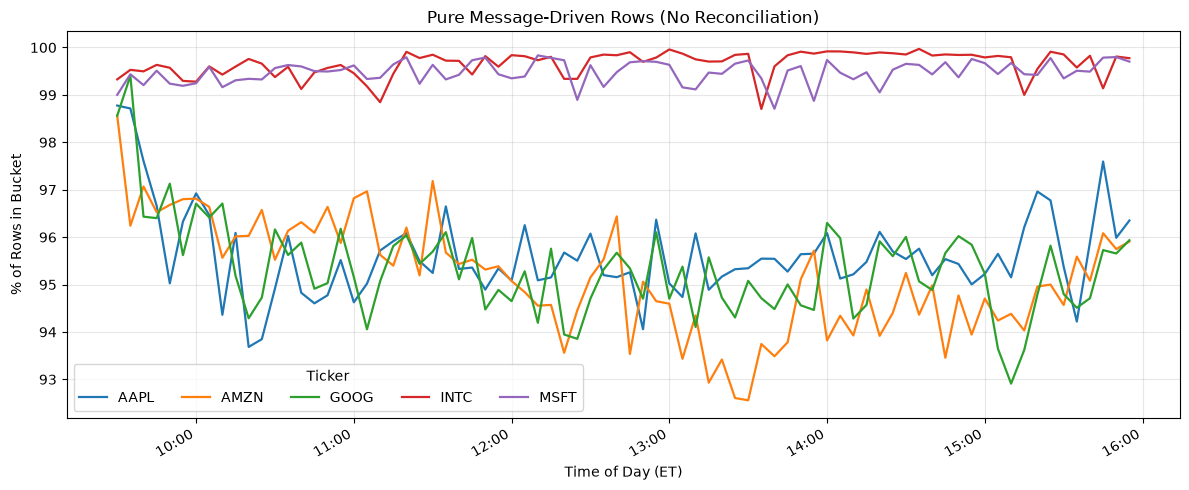

In [26]:
plot_metric("pure_message_driven", "Pure Message-Driven Rows (No Reconciliation)", "% of Rows in Bucket")

### Best Bid / Ask Price Agreement

Rows where our best price equalled LOBSTER's, before reconciliation.

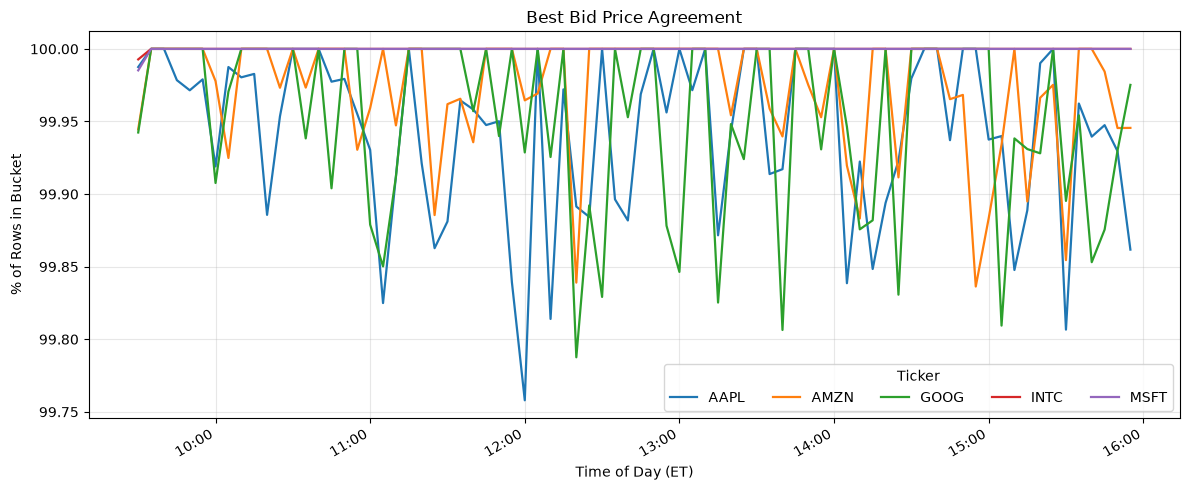

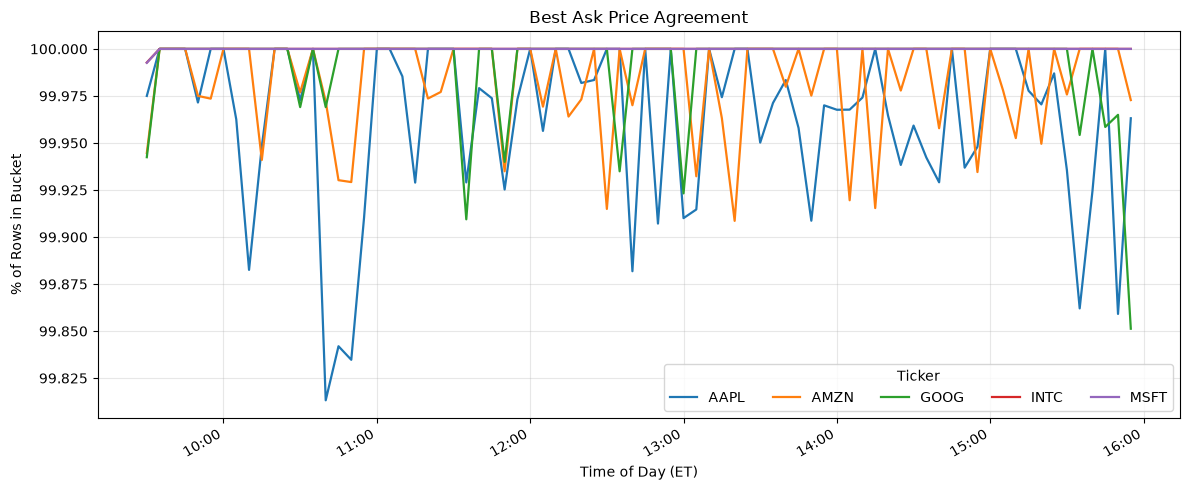

In [27]:
plot_metric("bid_price_agreement", "Best Bid Price Agreement", "% of Rows in Bucket")
plot_metric("ask_price_agreement", "Best Ask Price Agreement", "% of Rows in Bucket")

### Best Bid / Ask Touch Agreement (Price + Size)

Stricter than price alone: both the best price **and** its aggregate size matched, before reconciliation.

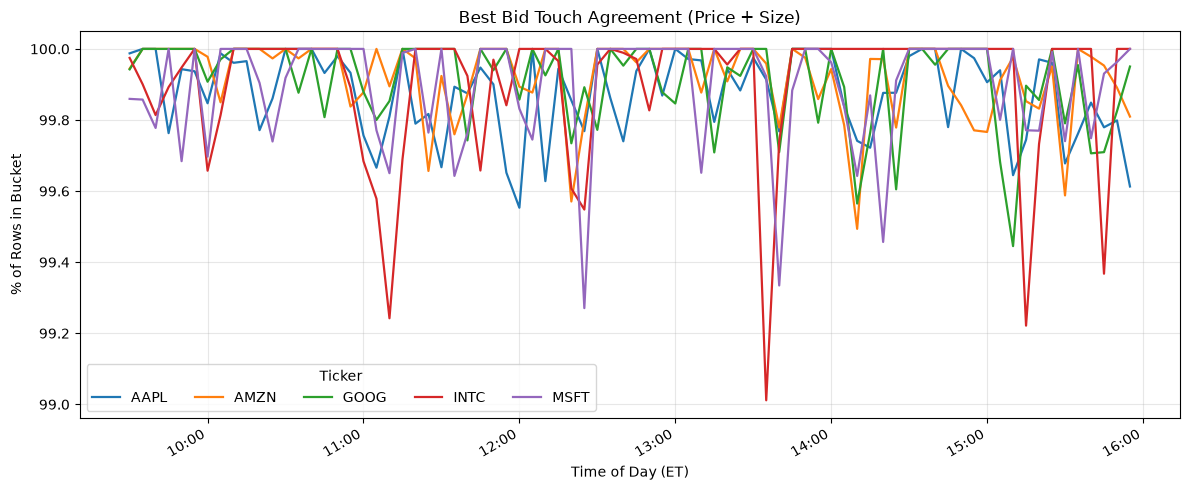

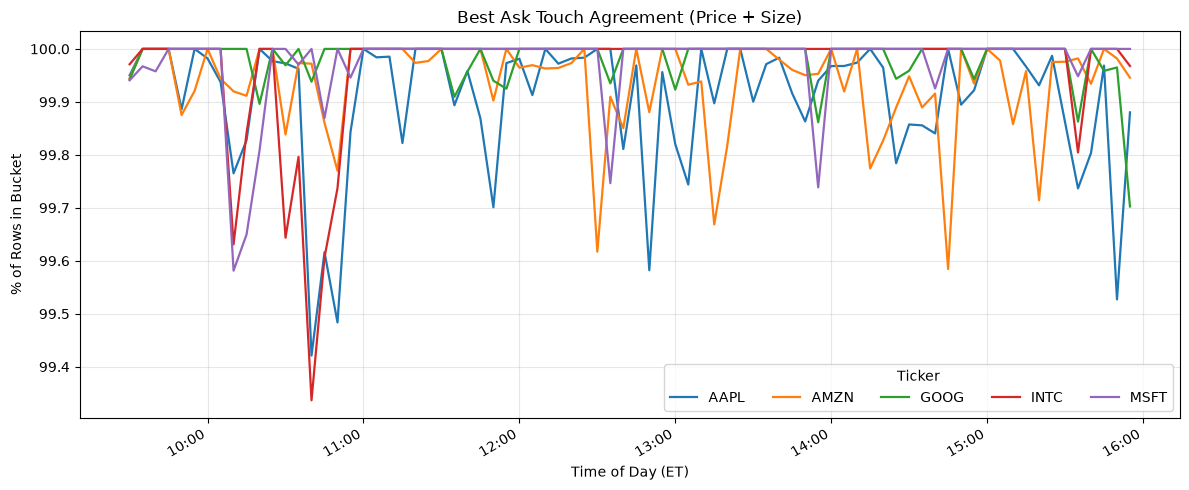

In [28]:
plot_metric("bid_touch_agreement", "Best Bid Touch Agreement (Price + Size)", "% of Rows in Bucket")
plot_metric("ask_touch_agreement", "Best Ask Touch Agreement (Price + Size)", "% of Rows in Bucket")

### Depth Error

`depth_abs_error / depth_true` over the visible top-10 band, both sides, before reconciliation. Lower is better.

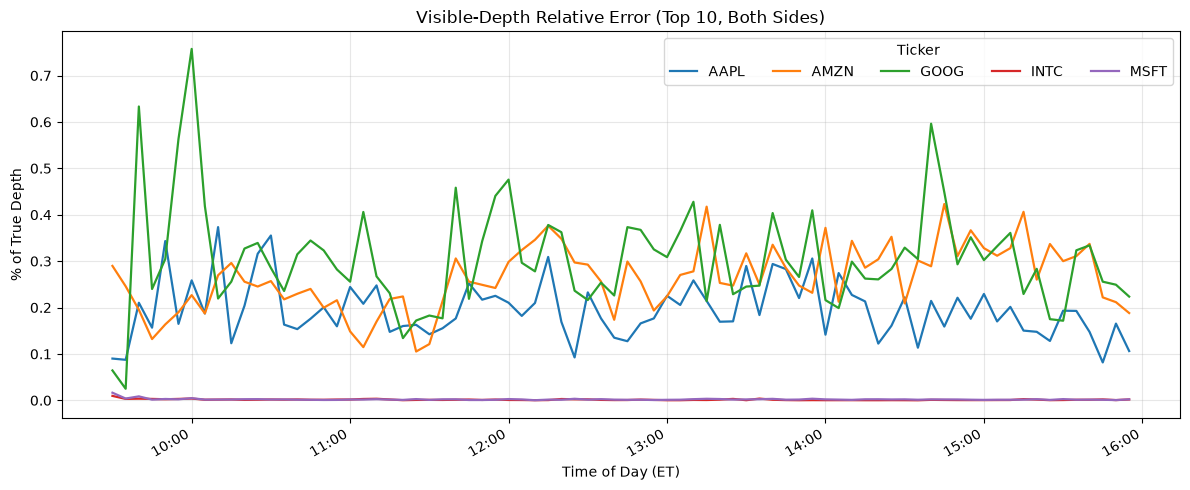

In [29]:
plot_metric("depth_error", "Visible-Depth Relative Error (Top 10, Both Sides)", "% of True Depth")

### Genesis Share of Touch Volume

Fraction of shares at the best price whose individual orders are unknown (genesis), after reconciliation. This is the uncertainty a quoting strategy would face at the touch.

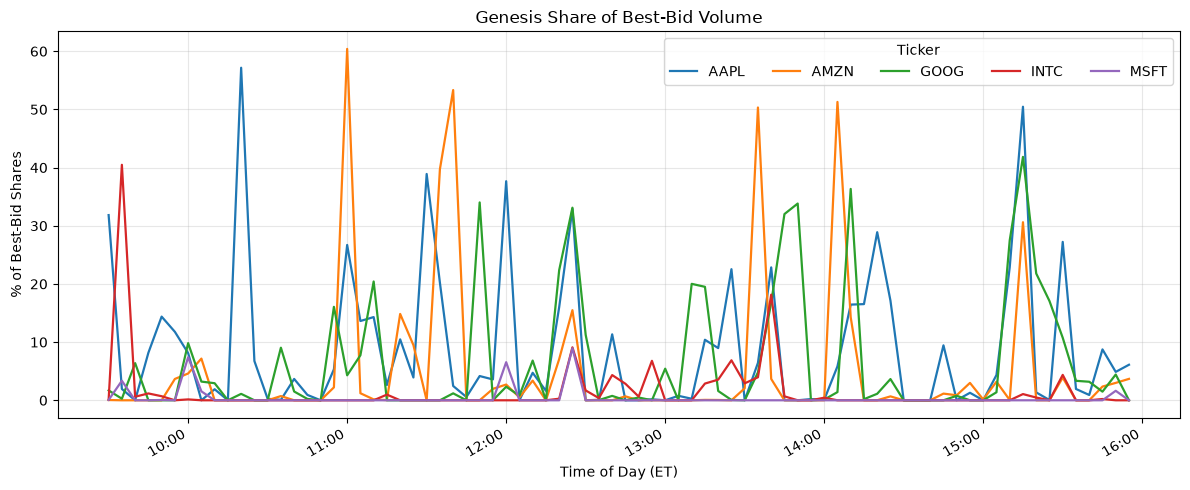

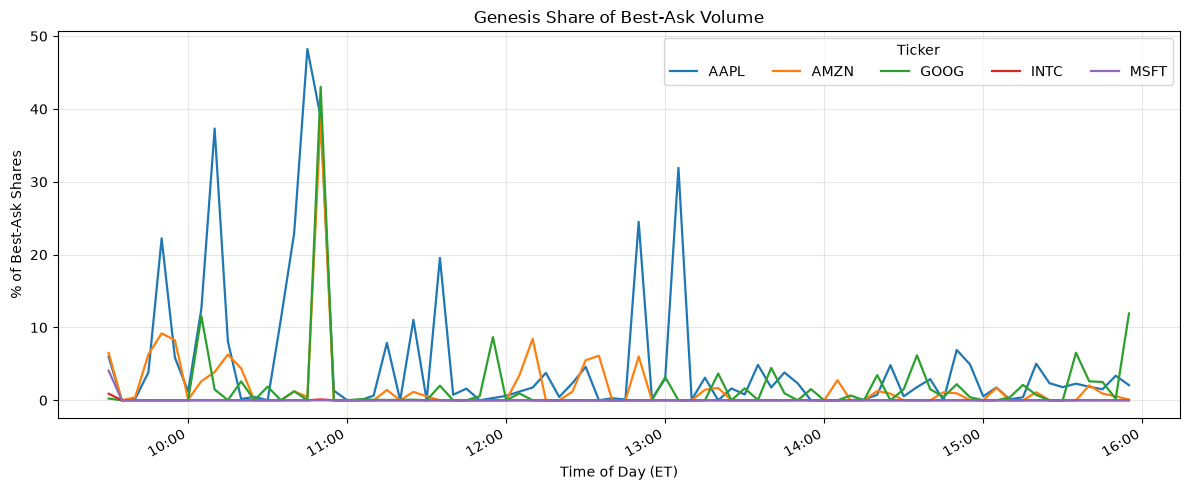

In [30]:
plot_metric("bid_genesis_share", "Genesis Share of Best-Bid Volume", "% of Best-Bid Shares")
plot_metric("ask_genesis_share", "Genesis Share of Best-Ask Volume", "% of Best-Ask Shares")

### Message Activity

Raw messages per 5-minute bucket. Ideally, the classic U-shape of intraday activity emerges.

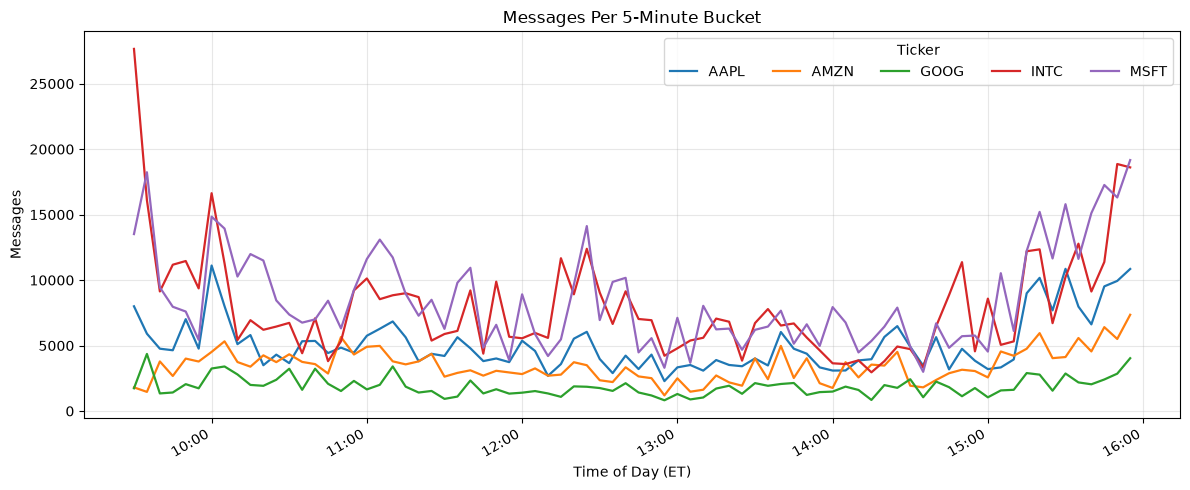

In [31]:
plot_metric("rows", "Messages Per 5-Minute Bucket", "Messages", as_percent=False)